# EAS Data Mining — Heart Attack Analysis & Prediction

**Dataset:** Heart Attack Analysis & Prediction Dataset (Kaggle)
**Tujuan:** Memprediksi risiko serangan jantung (output: 1 = risiko tinggi, 0 = risiko rendah) menggunakan teknik data mining.

**Alur notebook ini:**
1. Import Library & Load Data
2. Data Preprocessing (missing value, duplikat, outlier)
3. Summary Statistics & Visualisasi (EDA)
4. Feature Selection / Extraction
5. Classification Modeling (Logistic Regression & Random Forest)
6. Evaluasi: Repeated Holdout & K-Fold Cross Validation
7. Perbandingan Hasil & Kesimpulan


## 1. Import Library & Load Data

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.feature_selection import f_classif, mutual_info_classif
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import train_test_split, StratifiedKFold
from sklearn.metrics import (accuracy_score, confusion_matrix, roc_curve, auc,
                              roc_auc_score)

pd.set_option('display.max_columns', None)
sns.set_style("whitegrid")
plt.rcParams['figure.dpi'] = 100
np.random.seed(42)


In [2]:
df = pd.read_csv("../data/heart.csv")
print("Shape data:", df.shape)
df.head()


Shape data: (303, 14)


,age,sex,cp,trtbps,chol,fbs,restecg,thalachh,exng,oldpeak,slp,caa,thall,output
0,63,1,3,145,233,1,0,150,0,2.3,0,0,1,1
1,37,1,2,130,250,0,1,187,0,3.5,0,0,2,1
2,41,0,1,130,204,0,0,172,0,1.4,2,0,2,1
3,56,1,1,120,236,0,1,178,0,0.8,2,0,2,1
4,57,0,0,120,354,0,1,163,1,0.6,2,0,2,1


In [3]:
df.dtypes

age           int64
sex           int64
cp            int64
trtbps        int64
chol          int64
fbs           int64
restecg       int64
thalachh      int64
exng          int64
oldpeak     float64
slp           int64
caa           int64
thall         int64
output        int64
dtype: object

## 2. Data Preprocessing

Tahap ini memeriksa kualitas data sebelum dianalisis lebih lanjut: missing value, data duplikat, dan outlier.

In [4]:
print("=== MISSING VALUES ===")
print(df.isnull().sum())


=== MISSING VALUES ===
age         0
sex         0
cp          0
trtbps      0
chol        0
fbs         0
restecg     0
thalachh    0
exng        0
oldpeak     0
slp         0
caa         0
thall       0
output      0
dtype: int64


In [5]:
n_dup = df.duplicated().sum()
print(f"Jumlah baris duplikat: {n_dup}")

if n_dup > 0:
    df = df.drop_duplicates().reset_index(drop=True)
    print(f"Setelah hapus duplikat, shape: {df.shape}")


Jumlah baris duplikat: 1
Setelah hapus duplikat, shape: (302, 14)


In [6]:
desc = df.describe().T
desc


,count,mean,std,min,25%,50%,75%,max
age,302.0,54.420530,9.047970,29.0,48.00,55.5,61.00,77.0
sex,302.0,0.682119,0.466426,0.0,0.00,1.0,1.00,1.0
cp,302.0,0.963576,1.032044,0.0,0.00,1.0,2.00,3.0
trtbps,302.0,131.602649,17.563394,94.0,120.00,130.0,140.00,200.0
chol,302.0,246.500000,51.753489,126.0,211.00,240.5,274.75,564.0
fbs,302.0,0.149007,0.356686,0.0,0.00,0.0,0.00,1.0
restecg,302.0,0.526490,0.526027,0.0,0.00,1.0,1.00,2.0
thalachh,302.0,149.569536,22.903527,71.0,133.25,152.5,166.00,202.0
exng,302.0,0.327815,0.470196,0.0,0.00,0.0,1.00,1.0
oldpeak,302.0,1.043046,1.161452,0.0,0.00,0.8,1.60,6.2


**Deteksi outlier** menggunakan metode IQR (Interquartile Range) pada fitur numerik kontinu.

In [7]:
continuous_cols = ["age", "trtbps", "chol", "thalachh", "oldpeak"]

print("=== DETEKSI OUTLIER (metode IQR) ===")
for col in continuous_cols:
    Q1 = df[col].quantile(0.25)
    Q3 = df[col].quantile(0.75)
    IQR = Q3 - Q1
    lower = Q1 - 1.5 * IQR
    upper = Q3 + 1.5 * IQR
    n_outliers = ((df[col] < lower) | (df[col] > upper)).sum()
    print(f"{col}: {n_outliers} outlier (batas: {lower:.2f} - {upper:.2f})")


=== DETEKSI OUTLIER (metode IQR) ===
age: 0 outlier (batas: 28.50 - 80.50)
trtbps: 9 outlier (batas: 90.00 - 170.00)
chol: 5 outlier (batas: 115.38 - 370.38)
thalachh: 1 outlier (batas: 84.12 - 215.12)
oldpeak: 5 outlier (batas: -2.40 - 4.00)


Outlier yang ditemukan (pada `trtbps`, `chol`, `oldpeak`, `thalachh`) masih masuk akal secara klinis (misal kolesterol/tekanan darah tinggi pada pasien jantung), sehingga **tidak dihapus** — hanya dicatat sebagai catatan analisis.

In [8]:
print("=== DISTRIBUSI TARGET (output) ===")
print(df['output'].value_counts())
print(df['output'].value_counts(normalize=True) * 100)


=== DISTRIBUSI TARGET (output) ===
output
1    164
0    138
Name: count, dtype: int64
output
1    54.304636
0    45.695364
Name: proportion, dtype: float64


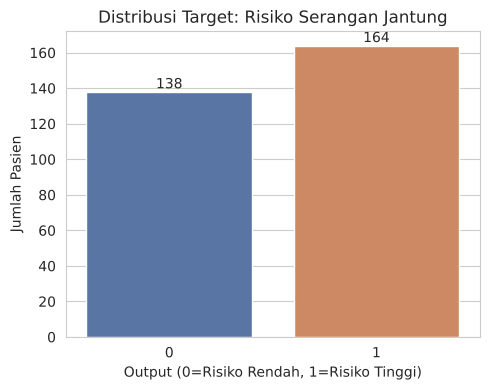

In [9]:
plt.figure(figsize=(5,4))
ax = sns.countplot(x='output', data=df, hue='output', legend=False, palette=['#4C72B0', '#DD8452'])
plt.title('Distribusi Target: Risiko Serangan Jantung')
plt.xlabel('Output (0=Risiko Rendah, 1=Risiko Tinggi)')
plt.ylabel('Jumlah Pasien')
for p_ in ax.patches:
    ax.annotate(f'{int(p_.get_height())}', (p_.get_x()+p_.get_width()/2, p_.get_height()+2), ha='center')
plt.tight_layout()
plt.savefig("../images/figures/01_target_distribution.png")
plt.show()


In [10]:
# Simpan data bersih untuk tahap selanjutnya
df.to_csv("../outputs/heart_clean.csv", index=False)
print("Data bersih disimpan. Shape final:", df.shape)


Data bersih disimpan. Shape final: (302, 14)


## 3. Summary Statistics dan Visualisasi (EDA)

Eksplorasi pola data numerik dan kategorikal terhadap target, serta korelasi antar fitur.

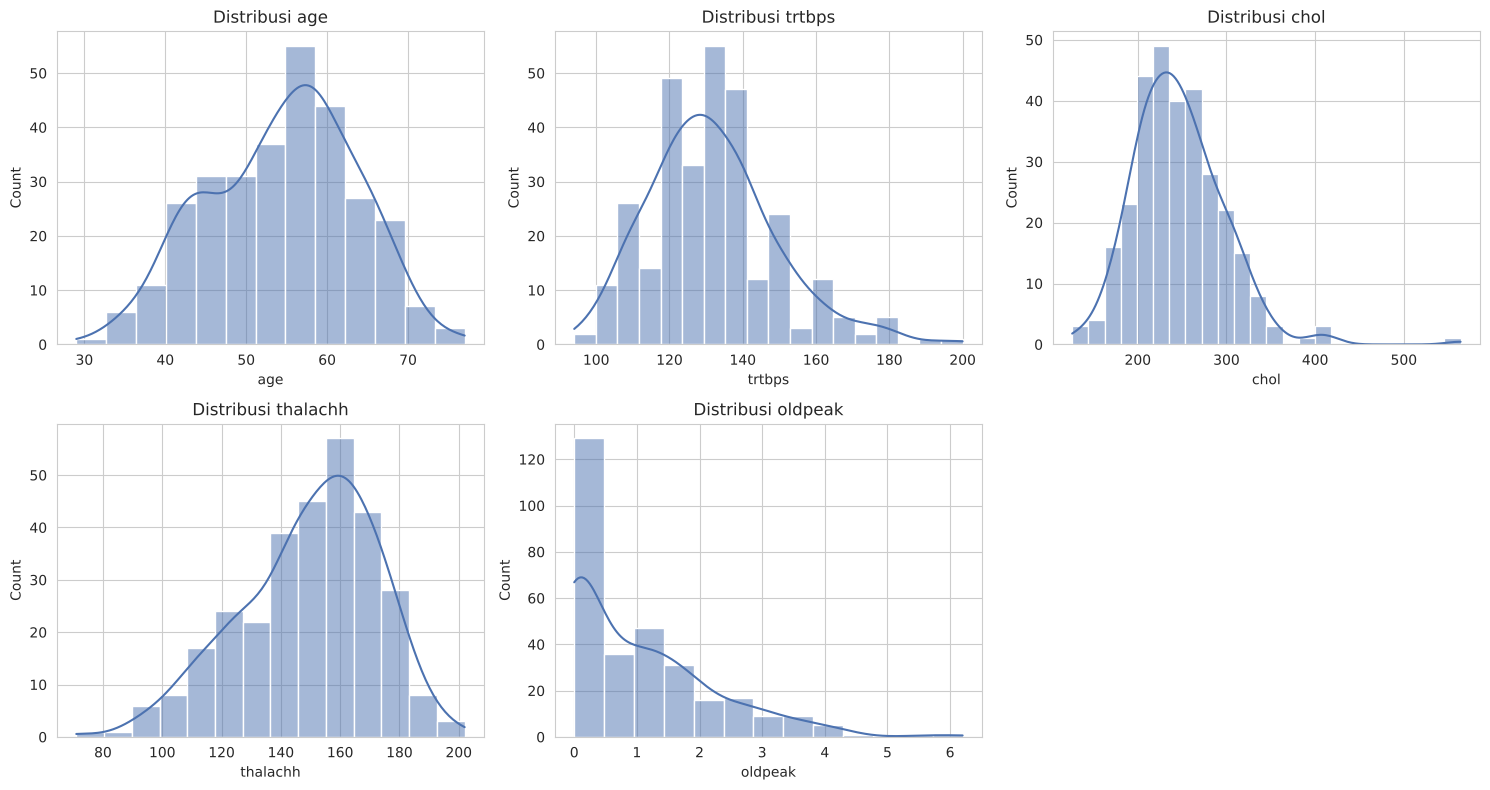

In [11]:
fig, axes = plt.subplots(2, 3, figsize=(15, 8))
for i, col in enumerate(continuous_cols):
    ax = axes[i // 3, i % 3]
    sns.histplot(df[col], kde=True, ax=ax, color='#4C72B0')
    ax.set_title(f'Distribusi {col}')
axes[1, 2].axis('off')
plt.tight_layout()
plt.savefig("../images/figures/02_histogram_numerik.png")
plt.show()


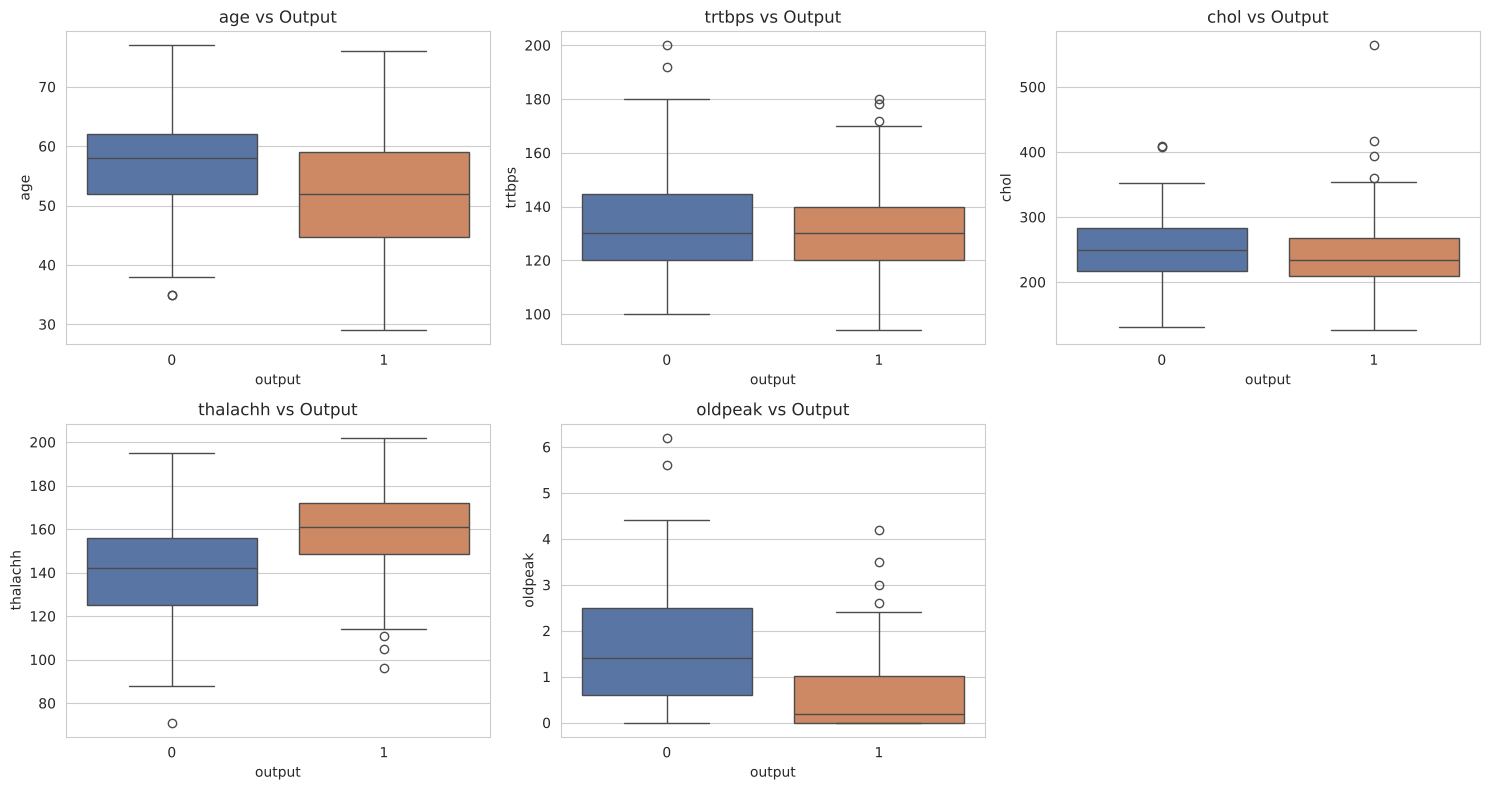

In [12]:
fig, axes = plt.subplots(2, 3, figsize=(15, 8))
for i, col in enumerate(continuous_cols):
    ax = axes[i // 3, i % 3]
    sns.boxplot(x='output', y=col, hue='output', legend=False, data=df, ax=ax, palette=['#4C72B0', '#DD8452'])
    ax.set_title(f'{col} vs Output')
axes[1, 2].axis('off')
plt.tight_layout()
plt.savefig("../images/figures/03_boxplot_vs_target.png")
plt.show()


Pasien berisiko tinggi (output=1) cenderung memiliki `thalachh` (denyut jantung maksimum) yang lebih tinggi dan `oldpeak` (ST depression) yang lebih rendah dibandingkan pasien berisiko rendah.

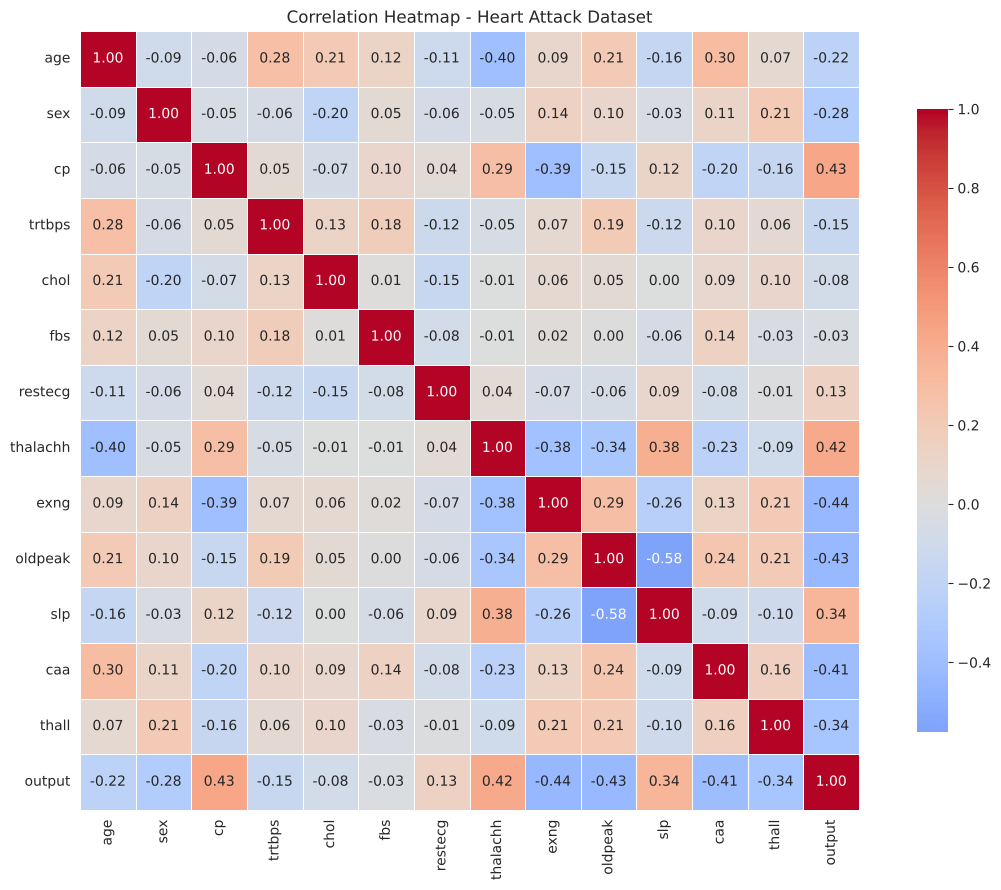

In [13]:
plt.figure(figsize=(12, 9))
corr = df.corr()
sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm", center=0, square=True,
            linewidths=0.5, cbar_kws={"shrink": 0.8})
plt.title('Correlation Heatmap - Heart Attack Dataset')
plt.tight_layout()
plt.savefig("../images/figures/04_correlation_heatmap.png")
plt.show()


In [14]:
corr_target = corr['output'].drop('output').sort_values(key=abs, ascending=False)
print("=== KORELASI DENGAN TARGET (output), diurutkan ===")
corr_target


=== KORELASI DENGAN TARGET (output), diurutkan ===


exng       -0.435601
cp          0.432080
oldpeak    -0.429146
thalachh    0.419955
caa        -0.408992
slp         0.343940
thall      -0.343101
sex        -0.283609
age        -0.221476
trtbps     -0.146269
restecg     0.134874
chol       -0.081437
fbs        -0.026826
Name: output, dtype: float64

Fitur dengan korelasi paling kuat terhadap target: `exng`, `cp`, `oldpeak`, `thalachh`, `caa`, `slp`. Sebaliknya, `fbs` dan `chol` berkorelasi sangat lemah.

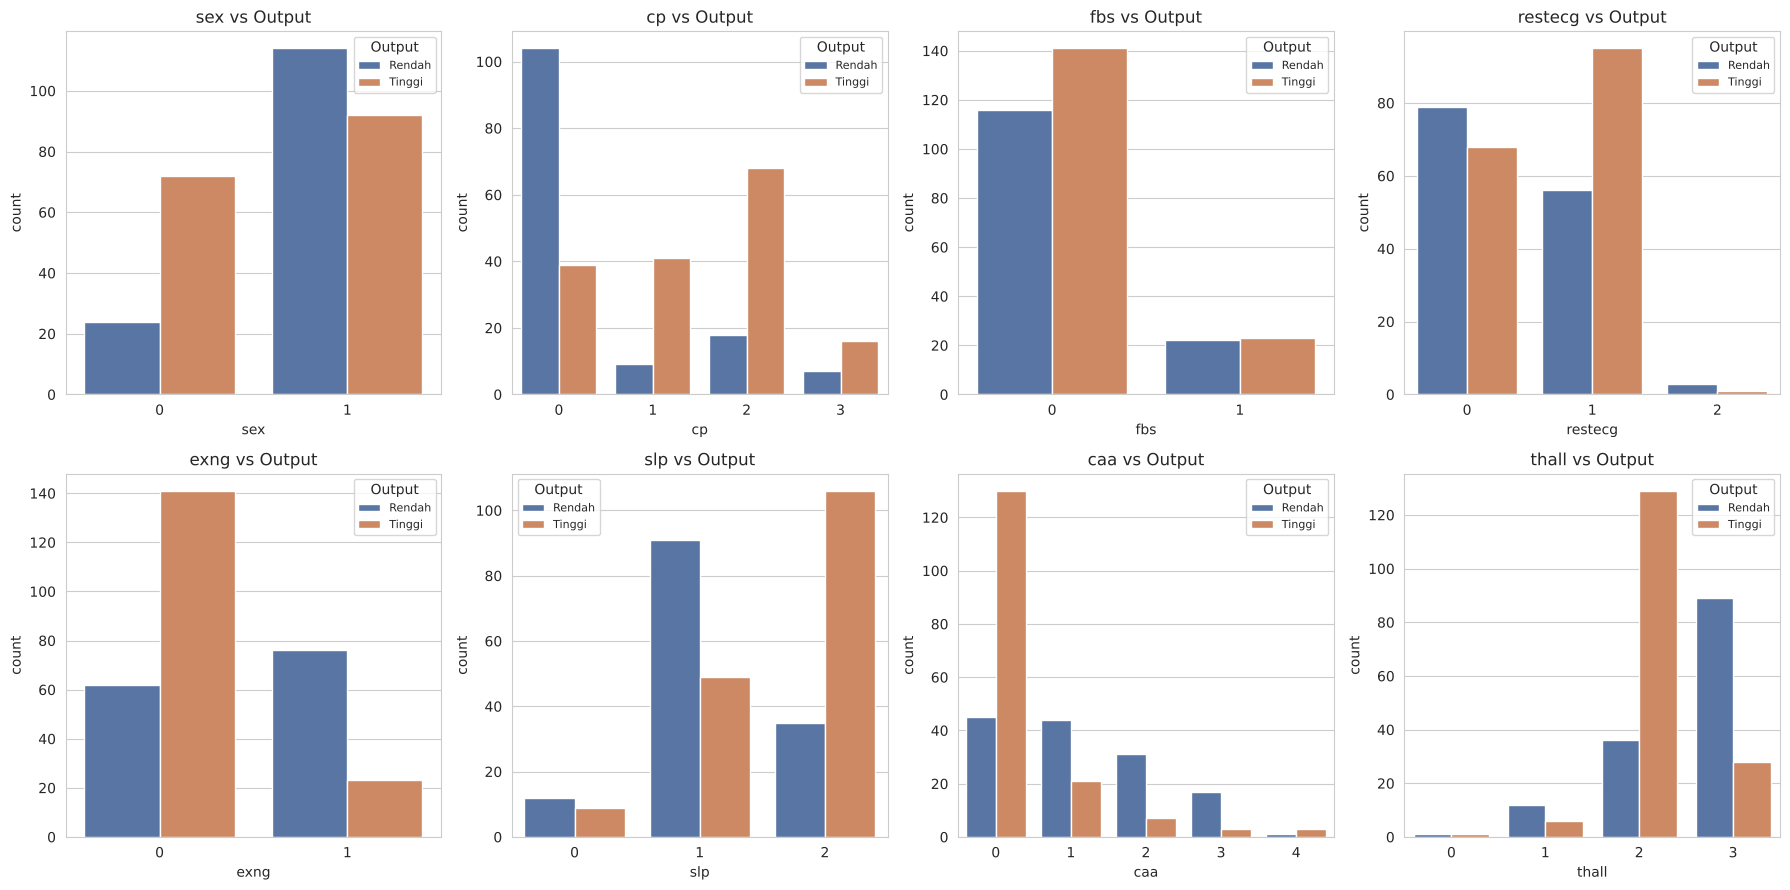

In [15]:
categorical_cols = ["sex", "cp", "fbs", "restecg", "exng", "slp", "caa", "thall"]
fig, axes = plt.subplots(2, 4, figsize=(18, 9))
for i, col in enumerate(categorical_cols):
    ax = axes[i // 4, i % 4]
    sns.countplot(x=col, hue='output', data=df, ax=ax, palette=['#4C72B0', '#DD8452'])
    ax.set_title(f'{col} vs Output')
    ax.legend(title='Output', labels=['Rendah', 'Tinggi'], fontsize=8)
plt.tight_layout()
plt.savefig("../images/figures/05_categorical_vs_target.png")
plt.show()


## 4. Feature Selection / Extraction

Tiga metode digunakan untuk memastikan ketahanan (robustness) hasil seleksi fitur:
- **ANOVA F-test** — signifikansi statistik univariat
- **Mutual Information** — dependensi non-linear fitur-target
- **Random Forest Feature Importance** — metode embedded berbasis decision tree


In [16]:
X = df.drop(columns=['output'])
y = df['output']
feature_names = X.columns.tolist()

f_scores, p_values = f_classif(X, y)
anova_df = pd.DataFrame({
    'feature': feature_names, 'F_score': f_scores, 'p_value': p_values
}).sort_values('F_score', ascending=False)

print("=== ANOVA F-TEST ===")
anova_df


=== ANOVA F-TEST ===


,feature,F_score,p_value
8,exng,70.255191,2.046468e-15
2,cp,68.864299,3.627384e-15
9,oldpeak,67.721931,5.814567e-15
7,thalachh,64.237793,2.476146e-14
11,caa,60.262749,1.317346e-13
10,slp,40.249626,8.221389e-10
12,thall,40.027376,9.089044e-10
1,sex,26.240952,5.402436e-07
0,age,15.474511,1.039484e-04
3,trtbps,6.558676,1.092654e-02


In [17]:
mi_scores = mutual_info_classif(X, y, random_state=42)
mi_df = pd.DataFrame({'feature': feature_names, 'MI_score': mi_scores}).sort_values('MI_score', ascending=False)

print("=== MUTUAL INFORMATION SCORE ===")
mi_df


=== MUTUAL INFORMATION SCORE ===


,feature,MI_score
2,cp,0.170884
12,thall,0.121040
9,oldpeak,0.097394
4,chol,0.086213
10,slp,0.079314
8,exng,0.076973
5,fbs,0.069578
7,thalachh,0.068254
11,caa,0.064985
6,restecg,0.047613


In [18]:
rf_temp = RandomForestClassifier(n_estimators=300, random_state=42)
rf_temp.fit(X, y)
rf_importance = pd.DataFrame({
    'feature': feature_names, 'importance': rf_temp.feature_importances_
}).sort_values('importance', ascending=False)

print("=== RANDOM FOREST FEATURE IMPORTANCE ===")
rf_importance


=== RANDOM FOREST FEATURE IMPORTANCE ===


,feature,importance
2,cp,0.139294
7,thalachh,0.123598
11,caa,0.113282
9,oldpeak,0.109709
12,thall,0.102585
0,age,0.091351
4,chol,0.076889
3,trtbps,0.075014
8,exng,0.053427
10,slp,0.049572


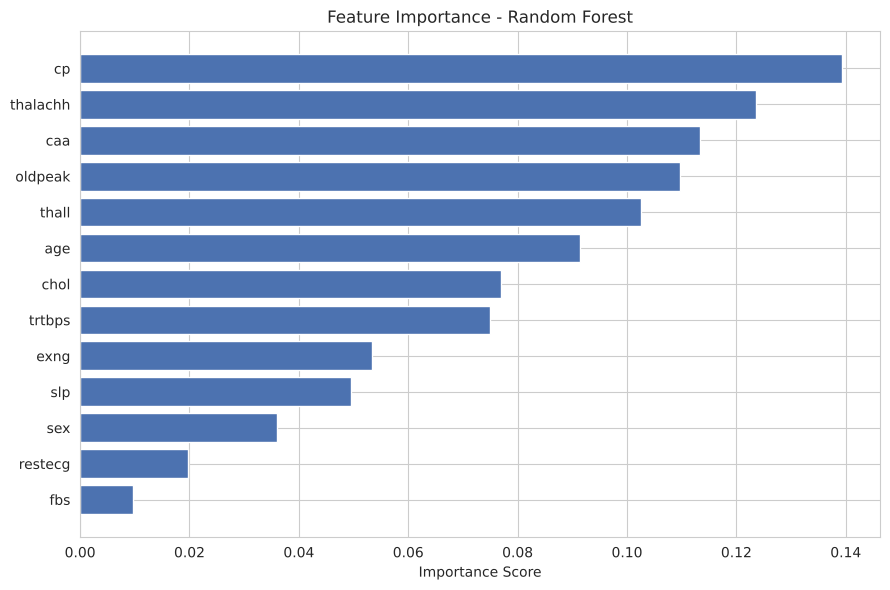

In [19]:
plt.figure(figsize=(9,6))
plot_df = rf_importance.sort_values('importance')
plt.barh(plot_df['feature'], plot_df['importance'], color='#4C72B0')
plt.xlabel('Importance Score')
plt.title('Feature Importance - Random Forest')
plt.tight_layout()
plt.savefig("../images/figures/06_feature_importance_rf.png")
plt.show()


In [20]:
# Ranking gabungan (rata-rata rank dari 3 metode)
combined = anova_df[['feature']].copy()
combined['rank_anova'] = anova_df['F_score'].rank(ascending=False).values
combined = combined.merge(
    mi_df.assign(rank_mi=mi_df['MI_score'].rank(ascending=False))[['feature', 'rank_mi']], on='feature')
combined = combined.merge(
    rf_importance.assign(rank_rf=rf_importance['importance'].rank(ascending=False))[['feature', 'rank_rf']], on='feature')
combined['avg_rank'] = combined[['rank_anova', 'rank_mi', 'rank_rf']].mean(axis=1)
combined = combined.sort_values('avg_rank')

print("=== RANKING GABUNGAN (rata-rata 3 metode) ===")
combined


=== RANKING GABUNGAN (rata-rata 3 metode) ===


,feature,rank_anova,rank_mi,rank_rf,avg_rank
1,cp,2.0,1.0,1.0,1.333333
2,oldpeak,3.0,3.0,4.0,3.333333
3,thalachh,4.0,8.0,2.0,4.666667
6,thall,7.0,2.0,5.0,4.666667
0,exng,1.0,6.0,9.0,5.333333
4,caa,5.0,9.0,3.0,5.666667
5,slp,6.0,5.0,10.0,7.000000
11,chol,12.0,4.0,7.0,7.666667
8,age,9.0,13.0,6.0,9.333333
7,sex,8.0,11.0,11.0,10.000000


In [21]:
top_features = combined['feature'].head(8).tolist()
print(f"Top 8 fitur terpilih: {top_features}")

combined.to_csv("../outputs/feature_ranking.csv", index=False)


Top 8 fitur terpilih: ['cp', 'oldpeak', 'thalachh', 'thall', 'exng', 'caa', 'slp', 'chol']


`cp`, `oldpeak`, `thalachh`, `thall`, `exng`, `caa` konsisten menjadi fitur paling penting di ketiga metode. Untuk pemodelan akhir, seluruh 13 fitur tetap digunakan (full feature set).

## 5. Classification Modeling

Dua metode klasifikasi digunakan:
- **Logistic Regression** — model linear, mudah diinterpretasi (odds ratio)
- **Random Forest** — model ensemble, menangkap hubungan non-linear

Evaluasi dilakukan dengan dua skema training-testing:
- **Repeated Holdout** (10x, split 70:30, stratified)
- **K-Fold Cross Validation** (k=10, stratified)

Metrik: Akurasi, Sensitivitas, Spesifisitas, ROC, dan AUC.


In [22]:
def specificity_score(y_true, y_pred):
    tn, fp, fn, tp = confusion_matrix(y_true, y_pred).ravel()
    return tn / (tn + fp)

def sensitivity_score(y_true, y_pred):
    tn, fp, fn, tp = confusion_matrix(y_true, y_pred).ravel()
    return tp / (tp + fn)

models = {
    "Logistic Regression": LogisticRegression(max_iter=2000, random_state=42),
    "Random Forest": RandomForestClassifier(n_estimators=300, random_state=42)
}

results_summary = []


### 5.1 Repeated Holdout (10 repetisi, split 70:30)

In [23]:
N_REPEATS = 10
holdout_results = {name: {"acc": [], "sens": [], "spec": [], "auc": []} for name in models}

for rep in range(N_REPEATS):
    X_train, X_test, y_train, y_test = train_test_split(
        X, y, test_size=0.3, stratify=y, random_state=rep
    )
    scaler = StandardScaler()
    X_train_s = scaler.fit_transform(X_train)
    X_test_s = scaler.transform(X_test)

    for name, model in models.items():
        model.fit(X_train_s, y_train)
        y_pred = model.predict(X_test_s)
        y_proba = model.predict_proba(X_test_s)[:, 1]

        holdout_results[name]["acc"].append(accuracy_score(y_test, y_pred))
        holdout_results[name]["sens"].append(sensitivity_score(y_test, y_pred))
        holdout_results[name]["spec"].append(specificity_score(y_test, y_pred))
        holdout_results[name]["auc"].append(roc_auc_score(y_test, y_proba))

print("Hasil rata-rata Repeated Holdout (10x, mean +/- std):\n")
for name in models:
    r = holdout_results[name]
    print(f"--- {name} ---")
    print(f"  Akurasi     : {np.mean(r['acc']):.4f} +/- {np.std(r['acc']):.4f}")
    print(f"  Sensitivitas: {np.mean(r['sens']):.4f} +/- {np.std(r['sens']):.4f}")
    print(f"  Spesifisitas: {np.mean(r['spec']):.4f} +/- {np.std(r['spec']):.4f}")
    print(f"  AUC         : {np.mean(r['auc']):.4f} +/- {np.std(r['auc']):.4f}")
    results_summary.append({
        "Model": name, "Metode Evaluasi": "Repeated Holdout (10x)",
        "Akurasi": np.mean(r['acc']), "Sensitivitas": np.mean(r['sens']),
        "Spesifisitas": np.mean(r['spec']), "AUC": np.mean(r['auc'])
    })


Hasil rata-rata Repeated Holdout (10x, mean +/- std):

--- Logistic Regression ---
  Akurasi     : 0.8396 +/- 0.0308
  Sensitivitas: 0.8816 +/- 0.0445
  Spesifisitas: 0.7905 +/- 0.0436
  AUC         : 0.9079 +/- 0.0294
--- Random Forest ---
  Akurasi     : 0.8220 +/- 0.0333
  Sensitivitas: 0.8449 +/- 0.0549
  Spesifisitas: 0.7952 +/- 0.0372
  AUC         : 0.9078 +/- 0.0249


### 5.2 K-Fold Cross Validation (k=10, stratified)

In [24]:
skf = StratifiedKFold(n_splits=10, shuffle=True, random_state=42)
kfold_results = {name: {"acc": [], "sens": [], "spec": [], "auc": []} for name in models}

X_arr = X.values
y_arr = y.values

for name in models:
    for fold, (train_idx, test_idx) in enumerate(skf.split(X_arr, y_arr)):
        X_train, X_test = X_arr[train_idx], X_arr[test_idx]
        y_train, y_test = y_arr[train_idx], y_arr[test_idx]

        scaler = StandardScaler()
        X_train_s = scaler.fit_transform(X_train)
        X_test_s = scaler.transform(X_test)

        if name == "Logistic Regression":
            m = LogisticRegression(max_iter=2000, random_state=42)
        else:
            m = RandomForestClassifier(n_estimators=300, random_state=42)

        m.fit(X_train_s, y_train)
        y_pred = m.predict(X_test_s)
        y_proba = m.predict_proba(X_test_s)[:, 1]

        kfold_results[name]["acc"].append(accuracy_score(y_test, y_pred))
        kfold_results[name]["sens"].append(sensitivity_score(y_test, y_pred))
        kfold_results[name]["spec"].append(specificity_score(y_test, y_pred))
        kfold_results[name]["auc"].append(roc_auc_score(y_test, y_proba))

print("Hasil rata-rata 10-Fold Cross Validation (mean +/- std):\n")
for name in models:
    r = kfold_results[name]
    print(f"--- {name} ---")
    print(f"  Akurasi     : {np.mean(r['acc']):.4f} +/- {np.std(r['acc']):.4f}")
    print(f"  Sensitivitas: {np.mean(r['sens']):.4f} +/- {np.std(r['sens']):.4f}")
    print(f"  Spesifisitas: {np.mean(r['spec']):.4f} +/- {np.std(r['spec']):.4f}")
    print(f"  AUC         : {np.mean(r['auc']):.4f} +/- {np.std(r['auc']):.4f}")
    results_summary.append({
        "Model": name, "Metode Evaluasi": "10-Fold Cross Validation",
        "Akurasi": np.mean(r['acc']), "Sensitivitas": np.mean(r['sens']),
        "Spesifisitas": np.mean(r['spec']), "AUC": np.mean(r['auc'])
    })


Hasil rata-rata 10-Fold Cross Validation (mean +/- std):

--- Logistic Regression ---
  Akurasi     : 0.8309 +/- 0.0610
  Sensitivitas: 0.8967 +/- 0.0620
  Spesifisitas: 0.7538 +/- 0.0849
  AUC         : 0.8985 +/- 0.0564
--- Random Forest ---
  Akurasi     : 0.8242 +/- 0.0603
  Sensitivitas: 0.8724 +/- 0.0836
  Spesifisitas: 0.7692 +/- 0.0872
  AUC         : 0.8997 +/- 0.0559


## 6. Perbandingan Hasil dan Visualisasi

In [25]:
summary_df = pd.DataFrame(results_summary)
summary_df.to_csv("../outputs/model_comparison_summary.csv", index=False)
summary_df


,Model,Metode Evaluasi,Akurasi,Sensitivitas,Spesifisitas,AUC
0,Logistic Regression,Repeated Holdout (10x),0.839560,0.881633,0.790476,0.907920
1,Random Forest,Repeated Holdout (10x),0.821978,0.844898,0.795238,0.907823
2,Logistic Regression,10-Fold Cross Validation,0.830860,0.896691,0.753846,0.898515
3,Random Forest,10-Fold Cross Validation,0.824194,0.872426,0.769231,0.899670


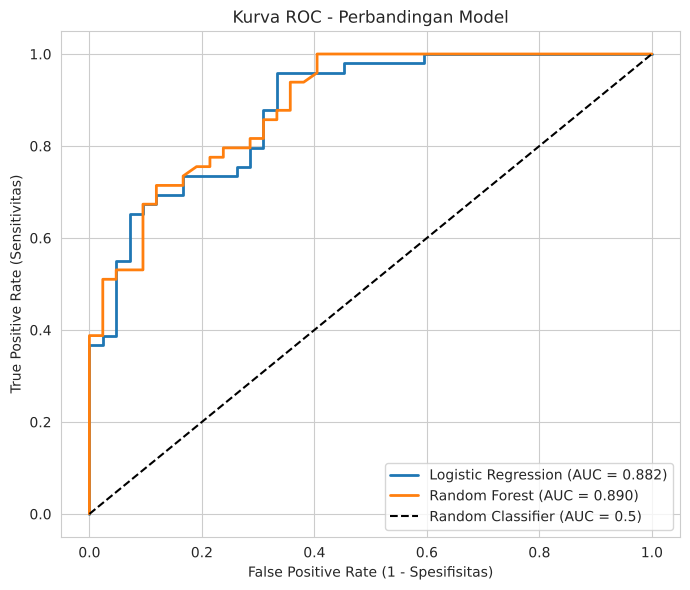

In [26]:
# ROC Curve (menggunakan 1 split holdout representatif untuk visualisasi)
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.3, stratify=y, random_state=42
)
scaler = StandardScaler()
X_train_s = scaler.fit_transform(X_train)
X_test_s = scaler.transform(X_test)

plt.figure(figsize=(7,6))
for name, model in models.items():
    model.fit(X_train_s, y_train)
    y_proba = model.predict_proba(X_test_s)[:, 1]
    fpr, tpr, _ = roc_curve(y_test, y_proba)
    roc_auc_val = auc(fpr, tpr)
    plt.plot(fpr, tpr, label=f"{name} (AUC = {roc_auc_val:.3f})", linewidth=2)

plt.plot([0, 1], [0, 1], 'k--', label='Random Classifier (AUC = 0.5)')
plt.xlabel('False Positive Rate (1 - Spesifisitas)')
plt.ylabel('True Positive Rate (Sensitivitas)')
plt.title('Kurva ROC - Perbandingan Model')
plt.legend(loc='lower right')
plt.tight_layout()
plt.savefig("../images/figures/07_roc_curve_comparison.png")
plt.show()


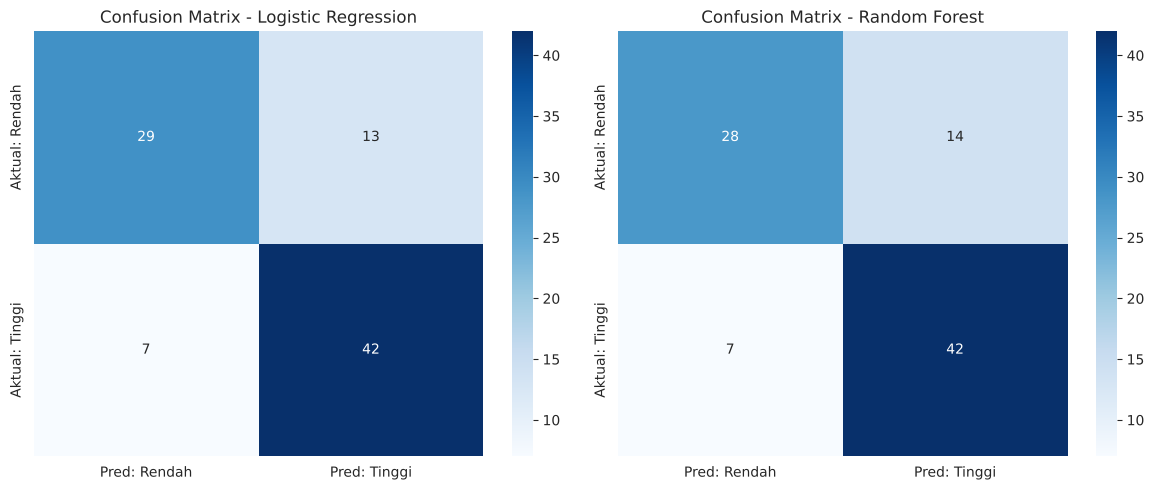

In [27]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5))
for i, (name, model) in enumerate(models.items()):
    y_pred = model.predict(X_test_s)
    cm = confusion_matrix(y_test, y_pred)
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', ax=axes[i],
                xticklabels=['Pred: Rendah', 'Pred: Tinggi'],
                yticklabels=['Aktual: Rendah', 'Aktual: Tinggi'])
    axes[i].set_title(f'Confusion Matrix - {name}')
plt.tight_layout()
plt.savefig("../images/figures/08_confusion_matrices.png")
plt.show()


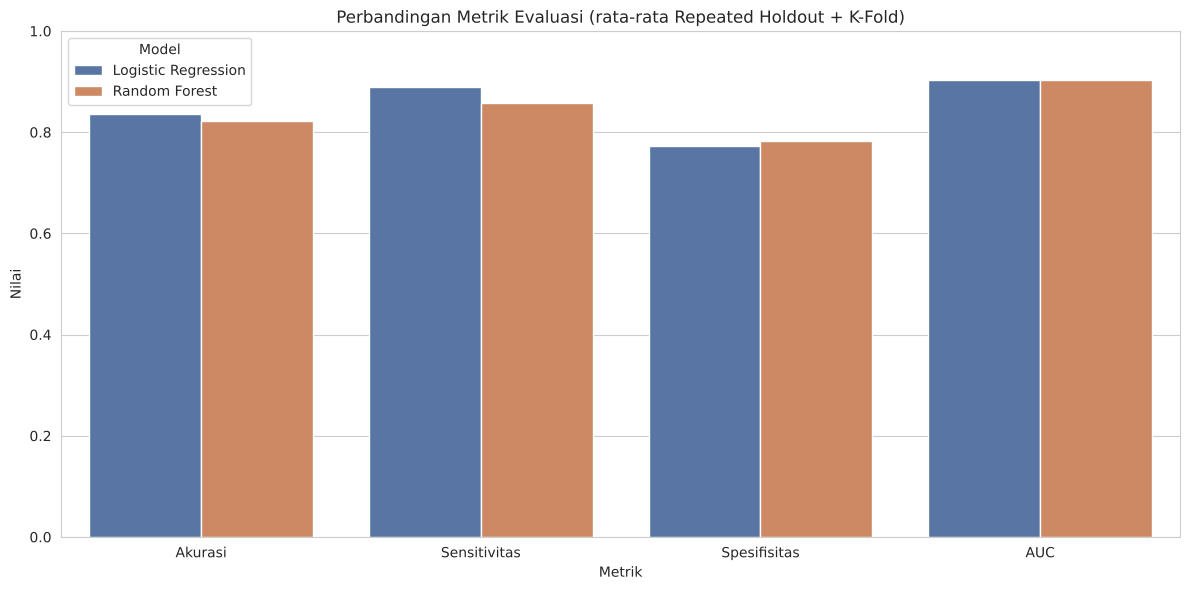

In [28]:
metrics_plot = summary_df.melt(id_vars=['Model', 'Metode Evaluasi'],
                                  value_vars=['Akurasi', 'Sensitivitas', 'Spesifisitas', 'AUC'],
                                  var_name='Metrik', value_name='Nilai')

plt.figure(figsize=(12, 6))
sns.barplot(data=metrics_plot, x='Metrik', y='Nilai', hue='Model',
            errorbar=None, palette=['#4C72B0', '#DD8452'])
plt.title('Perbandingan Metrik Evaluasi (rata-rata Repeated Holdout + K-Fold)')
plt.ylim(0, 1)
plt.legend(title='Model')
plt.tight_layout()
plt.savefig("../images/figures/09_metric_comparison_bar.png")
plt.show()


## 7. Kesimpulan

**Perbandingan performa:**
- **Logistic Regression** secara konsisten menghasilkan akurasi dan sensitivitas yang sedikit lebih tinggi dibandingkan **Random Forest** (akurasi ~83-84% vs ~82%), menunjukkan hubungan fitur-target pada dataset ini cenderung mendekati linear.
- **Random Forest** menghasilkan spesifisitas yang sedikit lebih baik pada skema Repeated Holdout (79.5% vs 79.0%).
- Nilai **AUC** kedua model sangat berdekatan dan tinggi (sekitar **0.90**), menunjukkan kemampuan diskriminasi yang sangat baik, jauh di atas classifier acak (AUC=0.5).
- Sensitivitas pada kedua model relatif lebih tinggi dibandingkan spesifisitas — secara klinis menguntungkan karena model lebih jarang melewatkan (false negative) pasien yang sebenarnya berisiko tinggi.

**Kesimpulan akhir:**
Kedua model menunjukkan performa yang sangat baik dan kompetitif. Pemilihan model akhir dapat didasarkan pada kebutuhan: **Logistic Regression** untuk interpretabilitas klinis (odds ratio), atau **Random Forest** untuk menangkap hubungan non-linear antar fitur. Fitur `cp`, `thalachh`, `oldpeak`, `thall`, `exng`, dan `caa` terbukti menjadi prediktor risiko serangan jantung yang paling kuat dan konsisten di seluruh metode feature selection yang digunakan.
